In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(37)  # For reproducibility
#A1, a
# Parameters
nu = 5
mu = 1
sigma = 0.01
n = 700
p = 0.975
q = 0.95

# Calculate the true 97.5% quantile
true_quantile = stats.t.ppf(p, df=nu, loc=mu, scale=sigma)

# Find the order statistic indices using the binomial distribution
r = 1 - p
alpha = 1 - q

j = 1
while stats.binom.cdf(j - 1, n, r) <= alpha / 2:
    j += 1

i = 1
while stats.binom.cdf(i - 1, n, r) < 1 - alpha / 2:
    i += 1

# Generate a sample and sort it in ascending order
sample = stats.t.rvs(df=nu, loc=mu, scale=sigma, size=n)
sorted_sample = np.sort(sample)

# Construct the confidence interval
lower = sorted_sample[n - i]
upper = sorted_sample[n - j+1]

# Calculate the actual coverage probability
lower_tail = 1 - stats.binom.cdf(i - 1, n, r)
upper_tail = stats.binom.cdf(j - 1, n, r)
coverage = 1 - lower_tail - upper_tail

# Print results
print("True quantile:", true_quantile)
print("Order statistics: i =", i -1, ", j =", j-2)
print("Confidence interval:", (lower, upper))
print("Coverage probability:", coverage)

# Check whether the interval contains the true quantile
print("Contains true quantile:", lower <= true_quantile <= upper)


True quantile: 1.0257058183563632
Order statistics: i = 26 , j = 9
Confidence interval: (np.float64(1.02473051640241), np.float64(1.0333053075029583))
Coverage probability: 0.9434529721239769
Contains true quantile: True


Theoretical VaR: 0.2570581835636321


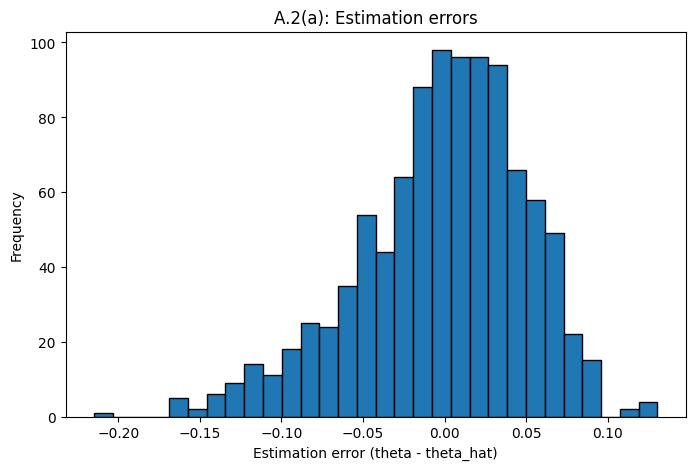

In [42]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(37)  # For reproducibility

# --------------------------------------------------
# Common parameters
# --------------------------------------------------

nu = 5
mu = 1
sigma = 0.01
V0 = 10
p = 0.975
q = 0.95
alpha = 1 - q


# --------------------------------------------------
# A.2(a): Theoretical VaR and estimation errors
# --------------------------------------------------

# Calculate the theoretical 2.5% quantile of returns
q_R = stats.t.ppf(p, df=nu, loc=mu, scale=sigma)

# Calculate the theoretical VaR
theta = V0 * (q_R - 1)

print("Theoretical VaR:", theta)

# Number of simulations and observations per simulation
N = 1000
n = 100

# Store the estimation errors
errors_a = []

for repetition in range(N):

    # Generate 100 independent returns
    returns = stats.t.rvs(df=nu, loc=mu, scale=sigma, size=n)

    # Convert returns into future net values
    X = V0 * (returns - 1)

    # Estimate VaR using the empirical 2.5% quantile
    theta_hat = -np.quantile(X, 1-p, method="inverted_cdf")

    # Calculate the estimation error
    errors_a.append(theta - theta_hat)

# Plot the histogram of estimation errors
plt.figure(figsize=(8, 5))
plt.hist(errors_a, bins=30, edgecolor="black")
plt.xlabel("Estimation error (theta - theta_hat)")
plt.ylabel("Frequency")
plt.title("A.2(a): Estimation errors")
plt.show()



Observed VaR estimate: 0.2686574325104152


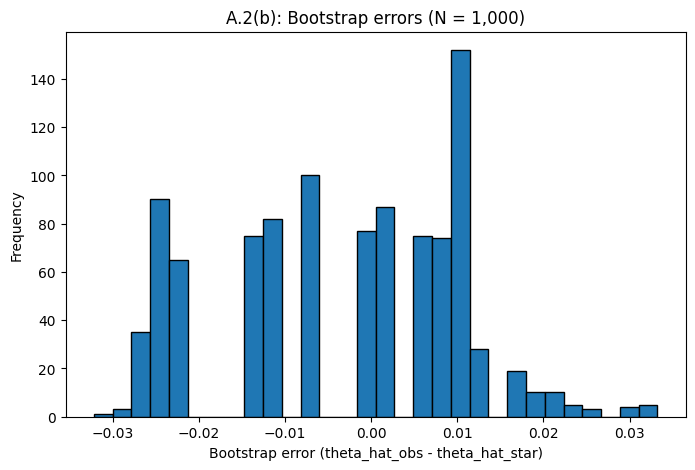

In [46]:

# --------------------------------------------------
# A.2(b): Bootstrap with 1,000 simulations
# --------------------------------------------------
np.random.seed(37) 
# Generate 700 historical observations
n = 700
returns_obs = stats.t.rvs(df=nu, loc=mu, scale=sigma, size=n)

# Convert historical returns into net values
X_obs = V0 * (returns_obs - 1)

# Calculate the empirical VaR from the historical data
theta_hat_obs = -np.quantile(X_obs, 1-p, method="inverted_cdf")

print("Observed VaR estimate:", theta_hat_obs)

# Number of bootstrap simulations
N_boot = 1000

# Store the bootstrap estimation errors
bootstrap_errors_b = []

for repetition in range(N_boot):

    # Draw a bootstrap sample with replacement
    X_star = np.random.choice(X_obs, size=n, replace=True)

    # Calculate the VaR estimate from the bootstrap sample
    theta_hat_star = -np.quantile(X_star, 1-p, method="inverted_cdf")

    # Calculate the difference between the observed and bootstrap estimates
    bootstrap_errors_b.append(theta_hat_obs - theta_hat_star)

# Plot the histogram of bootstrap errors
plt.figure(figsize=(8, 5))
plt.hist(bootstrap_errors_b, bins=30, edgecolor="black")
plt.xlabel("Bootstrap error (theta_hat_obs - theta_hat_star)")
plt.ylabel("Frequency")
plt.title("A.2(b): Bootstrap errors (N = 1,000)")
plt.show()

Observed VaR estimate: 0.2686574325104152


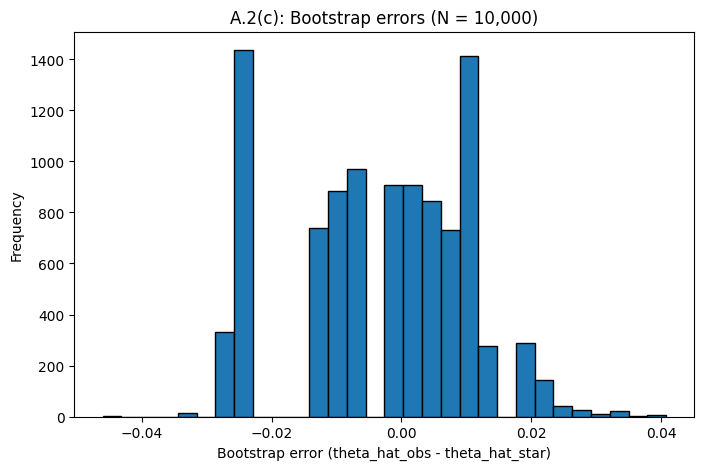

In [ ]:


# --------------------------------------------------
# A.2(c): Bootstrap with 10,000 simulations
# --------------------------------------------------

# Use the same historical observations as in part (b)
np.random.seed(37) 
# Generate 700 historical observations
n = 700
returns_obs = stats.t.rvs(df=nu, loc=mu, scale=sigma, size=n)

# Convert historical returns into net values
X_obs = V0 * (returns_obs - 1)

# Calculate the empirical VaR from the historical data
theta_hat_obs = -np.quantile(X_obs, 1-p, method="inverted_cdf")

print("Observed VaR estimate:", theta_hat_obs)

# Number of bootstrap simulations
N_boot = 10000

# Store the bootstrap estimation errors
bootstrap_errors_b = []

for repetition in range(N_boot):

    # Draw a bootstrap sample with replacement
    X_star = np.random.choice(X_obs, size=n, replace=True)

    # Calculate the VaR estimate from the bootstrap sample
    theta_hat_star = -np.quantile(X_star, 1-p, method="inverted_cdf")

    # Calculate the difference between the observed and bootstrap estimates
    bootstrap_errors_b.append(theta_hat_obs - theta_hat_star)

# Plot the histogram of bootstrap errors
plt.figure(figsize=(8, 5))
plt.hist(bootstrap_errors_b, bins=30, edgecolor="black")
plt.xlabel("Bootstrap error (theta_hat_obs - theta_hat_star)")
plt.ylabel("Frequency")
plt.title("A.2(c): Bootstrap errors (N = 10,000)")
plt.show()
#Comparing A.2(b) and A.2(c), we observe that increasing the number of 
# bootstrap simulations from 1,000 to 10,000 gives a more detailed representation 
# of the bootstrap error distribution. The distributions contain several distinct 
# peaks and are not particularly smooth or symmetric. This is partly because the 
# bootstrap samples are drawn from the original empirical dataset, and the inverted 
# empirical CDF quantile estimator can only select values from that dataset.Using more bootstrap
#  simulations does not provide additional historical information, but it improves the numerical 
# approximation of the bootstrap distribution.


True VaR: 0.25705818356363097


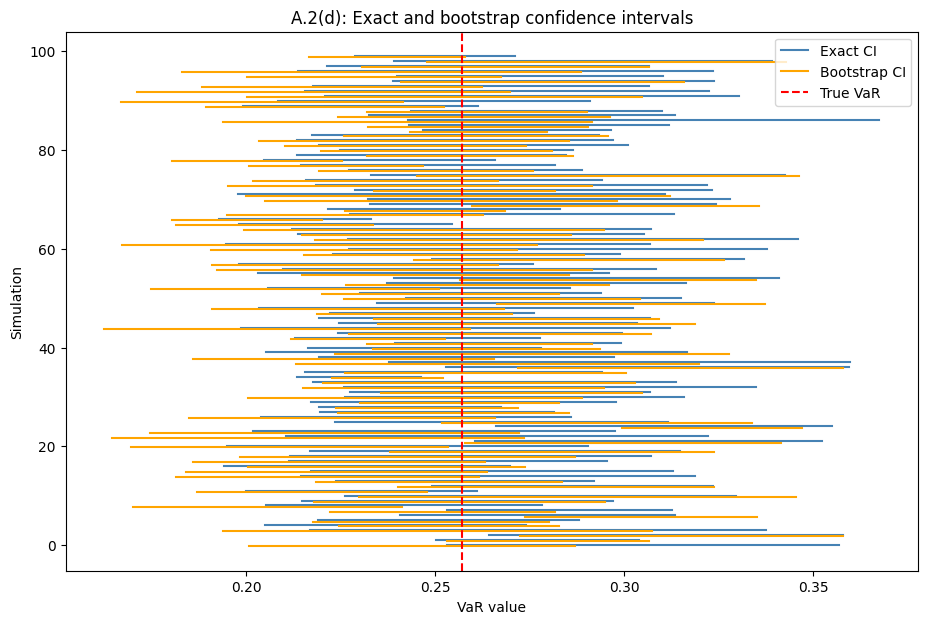

Exact intervals containing true VaR: 94 out of 100
Bootstrap intervals containing true VaR: 81 out of 100
Exact empirical coverage: 0.94
Bootstrap empirical coverage: 0.81


In [ ]:

# --------------------------------------------------
# A.2(d): Exact and bootstrap confidence intervals
# --------------------------------------------------

# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Set random seed for reproducibility
np.random.seed(37)

# Parameters
nu = 5
mu = 1
sigma = 0.01
V0 = 10

n = 700
p = 0.975
q = 0.95

K = 100
N_boot = 1000

# Calculate the true VaR
theta = -V0 * (stats.t.ppf(1-p, df=nu, loc=mu, scale=sigma) - 1)

print("True VaR:", theta)


# Function to calculate an exact confidence interval for VaR
def exact_var_ci(sample, p, confidence):

    n = len(sample)
    alpha = 1 - confidence
    tail_probability = 1 - p

    # Find the order statistic indices using the binomial distribution
    j = 1
    while stats.binom.cdf(j - 1, n, tail_probability) <= alpha / 2:
        j += 1

    i = 1
    while stats.binom.cdf(i - 1, n, tail_probability) < 1 - alpha / 2:
        i += 1

    # Sort the sample in ascending order
    sorted_sample = np.sort(sample)

    # Reverse and negate the endpoints to obtain the VaR interval
    lower = -sorted_sample[i - 1]
    upper = -sorted_sample[j - 1-1]

    return lower, upper


# Store the exact and bootstrap confidence intervals
exact_intervals = []
bootstrap_intervals = []

# Repeat the procedure K times
for repetition in range(K):

    # Generate a new historical dataset
    returns_obs = stats.t.rvs(
        df=nu, loc=mu, scale=sigma, size=n
    )

    # Convert returns into net values
    X_obs = V0 * (returns_obs - 1)

    # Calculate the exact confidence interval
    exact_ci = exact_var_ci(X_obs, p, q)
    exact_intervals.append(exact_ci)

    # Calculate the empirical VaR from the historical data
    theta_hat_obs = -np.quantile(
        X_obs, 1-p, method="inverted_cdf"
    )

    # Store bootstrap estimation errors
    bootstrap_errors = []

    # Generate N_boot bootstrap samples
    for b in range(N_boot):

        # Draw a sample with replacement
        X_star = np.random.choice(X_obs, size=n, replace=True)

        # Calculate the bootstrap VaR estimate
        theta_hat_star = -np.quantile(
            X_star, 1-p, method="inverted_cdf"
        )

        # Calculate the bootstrap error
        bootstrap_errors.append(theta_hat_obs - theta_hat_star)

    # Construct the basic bootstrap confidence interval
    lower = theta_hat_obs + np.quantile(bootstrap_errors, 0.025)
    upper = theta_hat_obs + np.quantile(bootstrap_errors, 0.975)

    bootstrap_intervals.append((lower, upper))


# Convert the intervals into NumPy arrays
exact_intervals = np.array(exact_intervals)
bootstrap_intervals = np.array(bootstrap_intervals)


# Plot both sets of confidence intervals
plt.figure(figsize=(11, 7))

for repetition in range(K):

    # Plot the exact confidence interval
    plt.plot(
        exact_intervals[repetition],
        [repetition, repetition],
        color="steelblue",
        label="Exact CI" if repetition == 0 else ""
    )

    # Plot the bootstrap confidence interval slightly below it
    plt.plot(
        bootstrap_intervals[repetition],
        [repetition - 0.25, repetition - 0.25],
        color="orange",
        label="Bootstrap CI" if repetition == 0 else ""
    )

# Plot the true VaR
plt.axvline(
    theta,
    color="red",
    linestyle="--",
    label="True VaR"
)

plt.xlabel("VaR value")
plt.ylabel("Simulation")
plt.title("A.2(d): Exact and bootstrap confidence intervals")
plt.legend()
plt.show()


# Calculate coverage of both methods
exact_coverage = sum(
    lower <= theta <= upper for lower, upper in exact_intervals
)

bootstrap_coverage = sum(
    lower <= theta <= upper for lower, upper in bootstrap_intervals
)

print("Exact intervals containing true VaR:", exact_coverage, "out of", K)
print("Bootstrap intervals containing true VaR:", bootstrap_coverage, "out of", K)
print("Exact empirical coverage:", exact_coverage / K)
print("Bootstrap empirical coverage:", bootstrap_coverage / K)
